# Filtro de Kalman paso a paso

## Idea central
Queremos conocer el **estado** de un sistema (por ejemplo, posición y velocidad de un móvil), pero solo tenemos **mediciones ruidosas** de una parte del estado (solo la posición).

El filtro de Kalman combina dos fuentes de información:

1. Un **modelo** de cómo evoluciona el sistema → la *predicción*.
2. Las **mediciones** ruidosas → la *corrección*.

Las pondera según su incertidumbre: confía más en quien tenga menos. Esa ponderación es la **ganancia de Kalman** ($K$).



## Glosario de símbolos

| Símbolo | Significado |
|---|---|
| $x$ | vector de estado estimado: `[posición, velocidad]` |
| $P$ | covarianza del estado: incertidumbre de la estimación |
| $F$ | matriz de transición: cómo evoluciona el estado en un paso |
| $G$ | cómo la aceleración aleatoria afecta al estado |
| $H$ | matriz de observación: qué parte del estado medimos |
| $Q$ | covarianza del ruido de proceso (incertidumbre del modelo) |
| $R$ | covarianza del ruido de medición (incertidumbre del sensor) |
| $z$ | medición |
| $y$ | innovación: medición − predicción |
| $S$ | covarianza de la innovación |
| $K$ | ganancia de Kalman |

In [1]:
import numpy as np                 
import matplotlib.pyplot as plt    

rng = np.random.default_rng(42)    
np.set_printoptions(precision=3, suppress=True)  

---
## Parte 1. Generación de datos sintéticos

**Escenario:** un objeto se mueve en línea recta con velocidad *casi* constante. Pequeñas aceleraciones aleatorias (viento, fricción…) lo desvían. Un sensor mide **solo la posición**, con mucho ruido.

- Estado: $x = [\text{posición},\ \text{velocidad}]^\top$ (la velocidad **no** se mide)
- Dinámica: $\text{pos}_k = \text{pos}_{k-1} + dt\cdot\text{vel}_{k-1}$ y $\text{vel}_k = \text{vel}_{k-1} + \text{aceleración aleatoria}$

In [3]:
# ---------- Parámetros de la simulación ----------
N = 100          # número de pasos de tiempo (cuántas mediciones tendremos)
DT = 1.0         # tiempo transcurrido entre dos pasos consecutivos
SIGMA_A = 0.2    # desv. estándar de la aceleración aleatoria (ruido de PROCESO: cuánto se desvía el móvil del modelo)
SIGMA_Z = 5.0    # desv. estándar del ruido del sensor (ruido de MEDICIÓN)
x0_real = np.array([0.0, 1.0])   # estado inicial real: [posición = 0, velocidad = 1]

# ---------- Matrices del modelo ----------
F = np.array([[1.0, DT],         # F: matriz de transición. Fila 1: pos_nueva = pos + DT*vel
              [0.0, 1.0]])       #                          Fila 2: vel_nueva = vel (velocidad constante)

G = np.array([[0.5 * DT**2],     # G: efecto de una aceleración 'a' sobre el estado.
              [DT]])             #    Posición cambia 0.5*a*DT², velocidad cambia a*DT

H = np.array([[1.0, 0.0]])       # H: matriz de observación. Medimos solo la posición (1ª componente)

Q = SIGMA_A**2 * (G @ G.T)       # Q: covarianza del ruido de proceso (2x2), construida con G
R = np.array([[SIGMA_Z**2]])     # R: covarianza del ruido de medición (1x1, una sola medición)

# ---------- Simulación de la trayectoria REAL (oculta al filtro) ----------
x_real = np.zeros((N, 2))        # x_real: trayectoria real; fila k = [posición_k, velocidad_k]
x_real[0] = x0_real              # condición inicial

for k in range(1, N):            # k: índice del paso de tiempo
    a = rng.normal(0.0, SIGMA_A)                       # a: aceleración aleatoria de este paso
    x_real[k] = F @ x_real[k - 1] + (G * a).ravel()    # avanzar el estado real un paso

# ---------- Mediciones ruidosas (lo ÚNICO que ve el filtro) ----------
ruido_z = rng.normal(0.0, SIGMA_Z, size=N)   # ruido_z: error aleatorio del sensor en cada paso
z = (x_real[:, 0] + ruido_z).reshape(-1, 1)  # z: mediciones = posición real + ruido (columna N x 1)

rmse_z = np.sqrt(np.mean((z[:, 0] - x_real[:, 0])**2))   # rmse_z: error cuadrático medio de la medición cruda
print(f"Pasos: {N} | dt = {DT} | sigma_a = {SIGMA_A} | sigma_z = {SIGMA_Z}")
print(f"RMSE de la medición cruda vs. posición real: {rmse_z:.3f}")

Pasos: 100 | dt = 1.0 | sigma_a = 0.2 | sigma_z = 5.0
RMSE de la medición cruda vs. posición real: 4.894


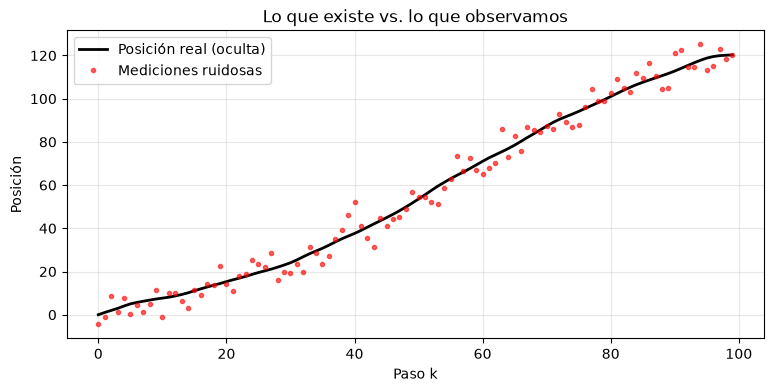

In [6]:
plt.figure(figsize=(9, 4))
plt.plot(x_real[:, 0], "k-", lw=2, label="Posición real (oculta)")
plt.plot(z[:, 0], "r.", alpha=0.6, label="Mediciones ruidosas")
plt.title("Lo que existe vs. lo que observamos")
plt.xlabel("Paso k"); plt.ylabel("Posición")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

---
## Parte 2. Un solo ciclo *predecir → actualizar*, desglosado

Antes de correr el filtro sobre toda la serie, veamos **un** ciclo con todos sus números.

Primero definimos la **creencia inicial**: qué sabemos antes de ver datos, y con cuánta incertidumbre.

In [ ]:
# ---------- Creencia inicial ----------
x0 = np.array([[z[0, 0]],        # x0: estado inicial supuesto (columna 2x1).
               [0.0]])           #     posición = primera medición; velocidad = 0 (no sabemos nada)

P0 = np.diag([SIGMA_Z**2,        # P0: incertidumbre inicial (2x2). Posición: tan incierta como el sensor.
              10.0**2])          #     Velocidad: muy incierta (±10), porque no la conocemos

x_demo = x0.copy()               # x_demo: copia del estado para esta demostración de un solo paso
P_demo = P0.copy()               # P_demo: copia de la covarianza para la demostración

print("Creencia inicial")
print("  estado x        =", x_demo.ravel(), "  (posición, velocidad)")
print("  desv. estándar  =", np.sqrt(np.diag(P_demo)))

Creencia inicial
  estado x        = [-4.527  0.   ]   (posición, velocidad)
  desv. estándar  = [ 5. 10.]


### Paso 1: PREDECIR
Proyectamos la creencia un instante hacia adelante usando el modelo. La media avanza con $F$ y la incertidumbre **crece** (se suma $Q$): el modelo no es perfecto.

In [5]:
x_pred = F @ x_demo                  # x_pred: estado predicho (a priori), x⁻ = F x
P_pred = F @ P_demo @ F.T + Q        # P_pred: covarianza predicha (a priori), P⁻ = F P Fᵀ + Q

print("Estado predicho x⁻        =", x_pred.ravel())
print("Desv. estándar tras predecir =", np.sqrt(np.diag(P_pred)), "  <- la incertidumbre creció")

Estado predicho x⁻        = [-4.527  0.   ]
Desv. estándar tras predecir = [11.181 10.002]   <- la incertidumbre creció


### Paso 2: ACTUALIZAR
Llega la medición $z_1$. Comparamos con lo que esperábamos ver y corregimos según la ganancia $K$.

In [ ]:
z1 = z[1].reshape(-1, 1)             # z1: medición del instante k=1 (columna 1x1)

z_pred = H @ x_pred                  # z_pred: medición que ESPERÁBAMOS ver según la predicción
y = z1 - z_pred                      # y: innovación = medición real - medición esperada ("la sorpresa")
S = H @ P_pred @ H.T + R             # S: covarianza de la innovación 
K = P_pred @ H.T @ np.linalg.inv(S)  # K: ganancia de Kalman (2x1). Cuánto creemos en la medición, si K es cercano a 0 confiamos en el modelo y no en la medicion, , 
                                        #si k es cercano a 1, creeo en la medicion y no en el modelo
                                        #Estado Corregido=Predicción+𝐾×(Medición−Predicción)

x_post = x_pred + K @ y              # x_post: estado corregido (a posteriori)

I2 = np.eye(2)                       # I2: matriz identidad 2x2
I_KH = I2 - K @ H                    # I_KH: (I - K H), factor auxiliar
P_post = I_KH @ P_pred @ I_KH.T + K @ R @ K.T   # P_post: covarianza corregida (forma de Joseph, estable numéricamente)

print(f"Medición z             = {z1.item():.3f}")
print(f"Predicción de z        = {z_pred.item():.3f}")
print(f"Innovación y           = {y.item():.3f}   (medición - predicción)")
print(f"Cov. innovación S      = {S.item():.3f}")
print(f"Ganancia K             = {K.ravel()}")
print("   K[0]: cuánto de la innovación se atribuye a la POSICIÓN")
print("   K[1]: cuánto a la VELOCIDAD (no la medimos, pero posición y velocidad")
print("         están correlacionadas en P, y por eso también se corrige)")
print(f"Estado posterior x     = {x_post.ravel()}")
print("Desv. estándar posterior =", np.sqrt(np.diag(P_post)), "  <- la incertidumbre bajó")

Medición z             = -0.860
Predicción de z        = -4.527
Innovación y           = 3.667   (medición - predicción)
Cov. innovación S      = 150.010
Ganancia K             = [0.833 0.667]
   K[0]: cuánto de la innovación se atribuye a la POSICIÓN
   K[1]: cuánto a la VELOCIDAD (no la medimos, pero posición y velocidad
         están correlacionadas en P, y por eso también se corrige)
Estado posterior x     = [-1.471  2.445]
Desv. estándar posterior = [4.564 5.775]   <- la incertidumbre bajó


---
## Parte 3. Aplicar el filtro a toda la serie

Repetimos el ciclo en cada instante $k$ y guardamos el historial para analizar los resultados.

In [7]:
x = x0.copy()                        # x: estado estimado actual (2x1). Se actualiza en cada paso
P = P0.copy()                        # P: covarianza actual (2x2). Se actualiza en cada paso

x_post_hist = np.zeros((N, 2))       # x_post_hist: estimación [pos, vel] después de corregir, en cada k
P_post_hist = np.zeros((N, 2, 2))    # P_post_hist: covarianza posterior en cada k
K_hist = np.zeros((N, 2))            # K_hist: ganancia de Kalman en cada k
innov = np.zeros(N)                  # innov: innovación y en cada k
S_hist = np.zeros(N)                 # S_hist: covarianza de la innovación S en cada k

for k in range(N):                   # k: índice del paso de tiempo
    # ----- PREDECIR (en k=0 la creencia inicial ya es a priori) -----
    if k > 0:
        x = F @ x                    # x⁻ = F x
        P = F @ P @ F.T + Q          # P⁻ = F P Fᵀ + Q

    # ----- ACTUALIZAR -----
    zk = z[k].reshape(-1, 1)         # zk: medición del instante k (1x1)
    yk = zk - H @ x                  # yk: innovación
    Sk = H @ P @ H.T + R             # Sk: covarianza de la innovación
    Kk = P @ H.T @ np.linalg.inv(Sk) # Kk: ganancia de Kalman

    x = x + Kk @ yk                  # corrección del estado
    I_KHk = np.eye(2) - Kk @ H       # I_KHk: (I - K H) en este paso
    P = I_KHk @ P @ I_KHk.T + Kk @ R @ Kk.T   # corrección de la covarianza (forma de Joseph)

    # ----- Guardar historial -----
    x_post_hist[k] = x.ravel()
    P_post_hist[k] = P
    K_hist[k] = Kk.ravel()
    innov[k] = yk.item()
    S_hist[k] = Sk.item()

print("Filtro aplicado a", N, "mediciones.")

Filtro aplicado a 100 mediciones.


---
## Parte 4. Resultados y diagnósticos

**Métricas de error** y tres **diagnósticos de calibración**:

- **Cobertura ±2σ:** si el filtro está bien calibrado, el valor real cae dentro de ±2σ ≈ 95 % de las veces.
- **NIS** (innovación² / S): debe promediar ≈ 1 (dimensión de $z$).
- **Innovaciones normalizadas** ($y/\sqrt{S}$): deben parecer ruido blanco $\mathcal{N}(0,1)$.

In [8]:
sd_pos = np.sqrt(P_post_hist[:, 0, 0])   # sd_pos: desv. estándar de la posición estimada en cada k
sd_vel = np.sqrt(P_post_hist[:, 1, 1])   # sd_vel: desv. estándar de la velocidad estimada en cada k
burn = 10                                 # burn: pasos iniciales que se descartan (transitorio del filtro)

rmse_kf_pos = np.sqrt(np.mean((x_post_hist[:, 0] - x_real[:, 0])**2))   # error del filtro en posición
rmse_kf_vel = np.sqrt(np.mean((x_post_hist[:, 1] - x_real[:, 1])**2))   # error del filtro en velocidad

print("=== Errores (RMSE) ===")
print(f"Posición  (medición cruda) : {rmse_z:.3f}")
print(f"Posición  (Kalman)         : {rmse_kf_pos:.3f}")
print(f"Velocidad (Kalman)         : {rmse_kf_vel:.3f}   <- ¡nunca la medimos!")

# --- Diagnóstico 1: cobertura ±2σ ---
dentro = np.abs(x_post_hist[burn:, 0] - x_real[burn:, 0]) <= 2 * sd_pos[burn:]   # dentro: True si el real cae en ±2σ
print("\n=== Diagnósticos de calibración ===")
print(f"Cobertura ±2σ de la posición real: {100 * dentro.mean():.1f} %  (esperado ≈ 95 %)")

# --- Diagnóstico 2: NIS ---
nis = innov**2 / S_hist                  # nis: error de innovación normalizado en cada k
print(f"NIS medio: {nis[burn:].mean():.2f}  (esperado ≈ 1.0)")

# --- Diagnóstico 3: innovaciones normalizadas ---
innov_norm = innov / np.sqrt(S_hist)     # innov_norm: innovación dividida entre su desv. estándar esperada
print(f"Innovaciones normalizadas: media = {innov_norm[burn:].mean():.2f}, "
      f"desv. est. = {innov_norm[burn:].std():.2f}  (esperado ≈ 0 y 1)")

=== Errores (RMSE) ===
Posición  (medición cruda) : 4.894
Posición  (Kalman)         : 2.224
Velocidad (Kalman)         : 0.698   <- ¡nunca la medimos!

=== Diagnósticos de calibración ===
Cobertura ±2σ de la posición real: 98.9 %  (esperado ≈ 95 %)
NIS medio: 0.99  (esperado ≈ 1.0)
Innovaciones normalizadas: media = -0.01, desv. est. = 1.00  (esperado ≈ 0 y 1)


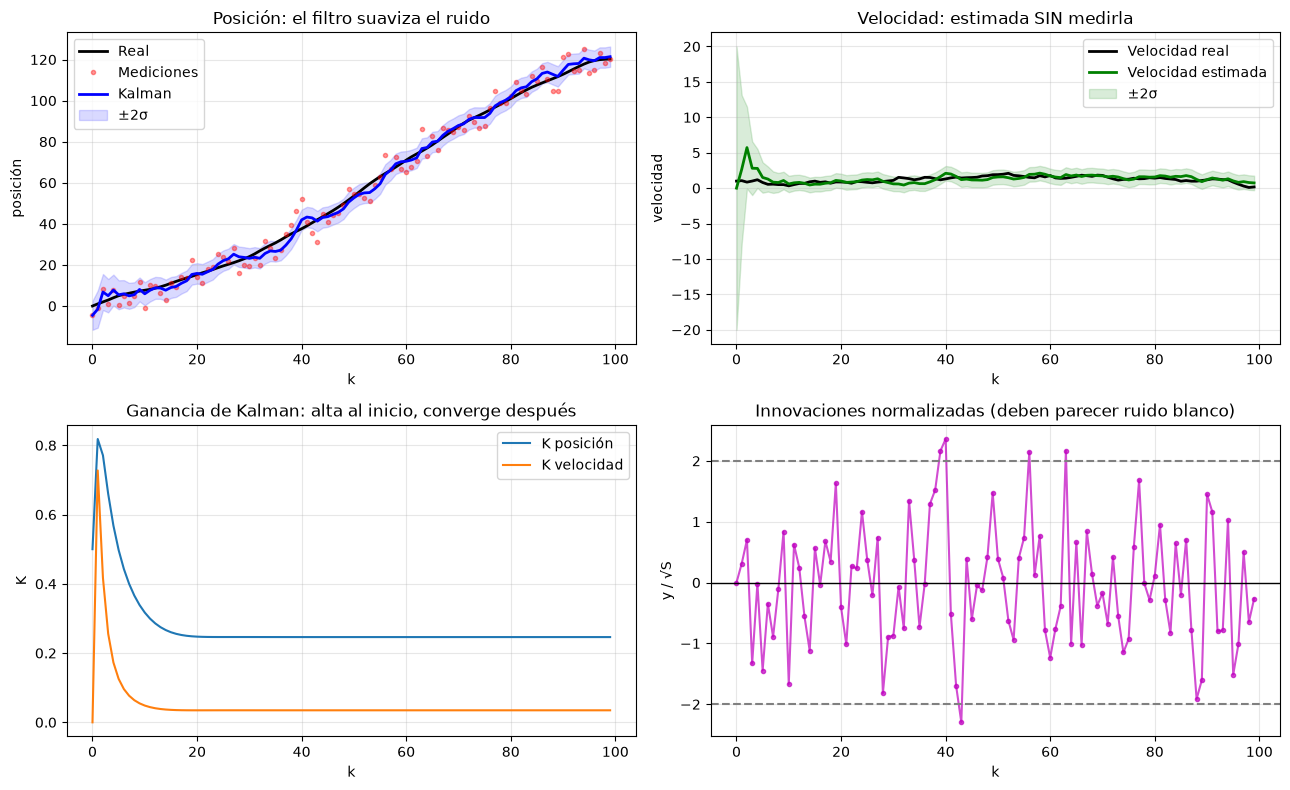

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(13, 8))   # fig, axs: figura y sus 4 paneles

# Panel 1: posición
axs[0, 0].plot(x_real[:, 0], "k-", lw=2, label="Real")
axs[0, 0].plot(z[:, 0], "r.", alpha=0.4, label="Mediciones")
axs[0, 0].plot(x_post_hist[:, 0], "b-", lw=2, label="Kalman")
axs[0, 0].fill_between(range(N), x_post_hist[:, 0] - 2 * sd_pos,
                       x_post_hist[:, 0] + 2 * sd_pos, color="b", alpha=0.15, label="±2σ")
axs[0, 0].set(title="Posición: el filtro suaviza el ruido", xlabel="k", ylabel="posición")
axs[0, 0].legend(); axs[0, 0].grid(alpha=0.3)

# Panel 2: velocidad (nunca medida)
axs[0, 1].plot(x_real[:, 1], "k-", lw=2, label="Velocidad real")
axs[0, 1].plot(x_post_hist[:, 1], "g-", lw=2, label="Velocidad estimada")
axs[0, 1].fill_between(range(N), x_post_hist[:, 1] - 2 * sd_vel,
                       x_post_hist[:, 1] + 2 * sd_vel, color="g", alpha=0.15, label="±2σ")
axs[0, 1].set(title="Velocidad: estimada SIN medirla", xlabel="k", ylabel="velocidad")
axs[0, 1].legend(); axs[0, 1].grid(alpha=0.3)

# Panel 3: ganancia de Kalman
axs[1, 0].plot(K_hist[:, 0], label="K posición")
axs[1, 0].plot(K_hist[:, 1], label="K velocidad")
axs[1, 0].set(title="Ganancia de Kalman: alta al inicio, converge después", xlabel="k", ylabel="K")
axs[1, 0].legend(); axs[1, 0].grid(alpha=0.3)

# Panel 4: innovaciones normalizadas
axs[1, 1].plot(innov_norm, "m.-", alpha=0.7)
axs[1, 1].axhline(0, color="k", lw=1)
axs[1, 1].axhline(2, color="gray", ls="--"); axs[1, 1].axhline(-2, color="gray", ls="--")
axs[1, 1].set(title="Innovaciones normalizadas (deben parecer ruido blanco)", xlabel="k", ylabel="y / √S")
axs[1, 1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

### Conclusión
El filtro óptimo **no** es el que "más suaviza", sino el que mejor refleja la incertidumbre real del modelo ($Q$) y del sensor ($R$).
